# 大模型微调 02：主流大模型介绍

本篇对应第二章资料，整理自 `02-笔记/Day02 笔记.md` 以及 `02-课件/第二章：主流大模型介绍` 下的两份课件。内容先回顾 GPT-1、GPT-2、GPT-3 到 ChatGPT 的演进，再介绍 ChatGLM、LLaMA、BLOOM、Baichuan 和 Qwen 等主流开源模型。

本章的主线是：**模型规模和数据不断扩大，训练目标从预训练加任务微调，逐渐发展到 zero-shot、few-shot 和基于人类反馈的对齐；开源模型则在架构、分词、位置编码、注意力和推理效率上做出不同取舍。**


## 一、GPT 系列与 ChatGPT 的发展路线

| 模型 | 时间 | 训练/使用方式 | 关键变化 |
| --- | --- | --- | --- |
| GPT-1 | 2018 年 6 月 | 无监督预训练 + 下游任务微调 | 用 Decoder-only Transformer 做生成式预训练 |
| GPT-2 | 2019 年 2 月 | 只做无监督预训练 | 更大数据和参数，强调 zero-shot |
| GPT-3 | 2020 年 5 月 | 只做预训练，测试时给提示和示例 | few-shot / in-context learning，加入 sparse attention |
| ChatGPT | 2022 年 11 月 30 日 | SFT + 奖励模型 + PPO | 用人类反馈改善对话一致性和偏好对齐 |

GPT-1 到 GPT-3 的模型结构都沿用了 Transformer Decoder-only 路线，主要变化来自参数规模、训练数据、上下文长度、注意力设计和使用方式。ChatGPT 并不是一套完全不同的基础架构，而是建立在 GPT 生成能力上，并通过人类反馈进一步训练得到的对话模型。


## 二、GPT-1：预训练加任务微调

### 2.1 基本信息与模型结构

GPT-1 由 OpenAI 于 2018 年提出，论文是 *Improving Language Understanding by Generative Pre-training*，模型参数约 1.17 亿。它使用传统语言模型目标，根据上文预测下一个词，因此更擅长自然语言生成（NLG）；相较之下，BERT 的双向编码更偏向自然语言理解（NLU）。

GPT 使用 Transformer 的 Decoder 模块，但去除了经典 Encoder-Decoder Decoder 中的第二个 encoder-decoder attention 子层，只保留 masked multi-head attention 和 feed-forward。课件对比中，经典 Transformer Decoder 使用 6 个 block，而 GPT-1 使用 12 个 Decoder block。


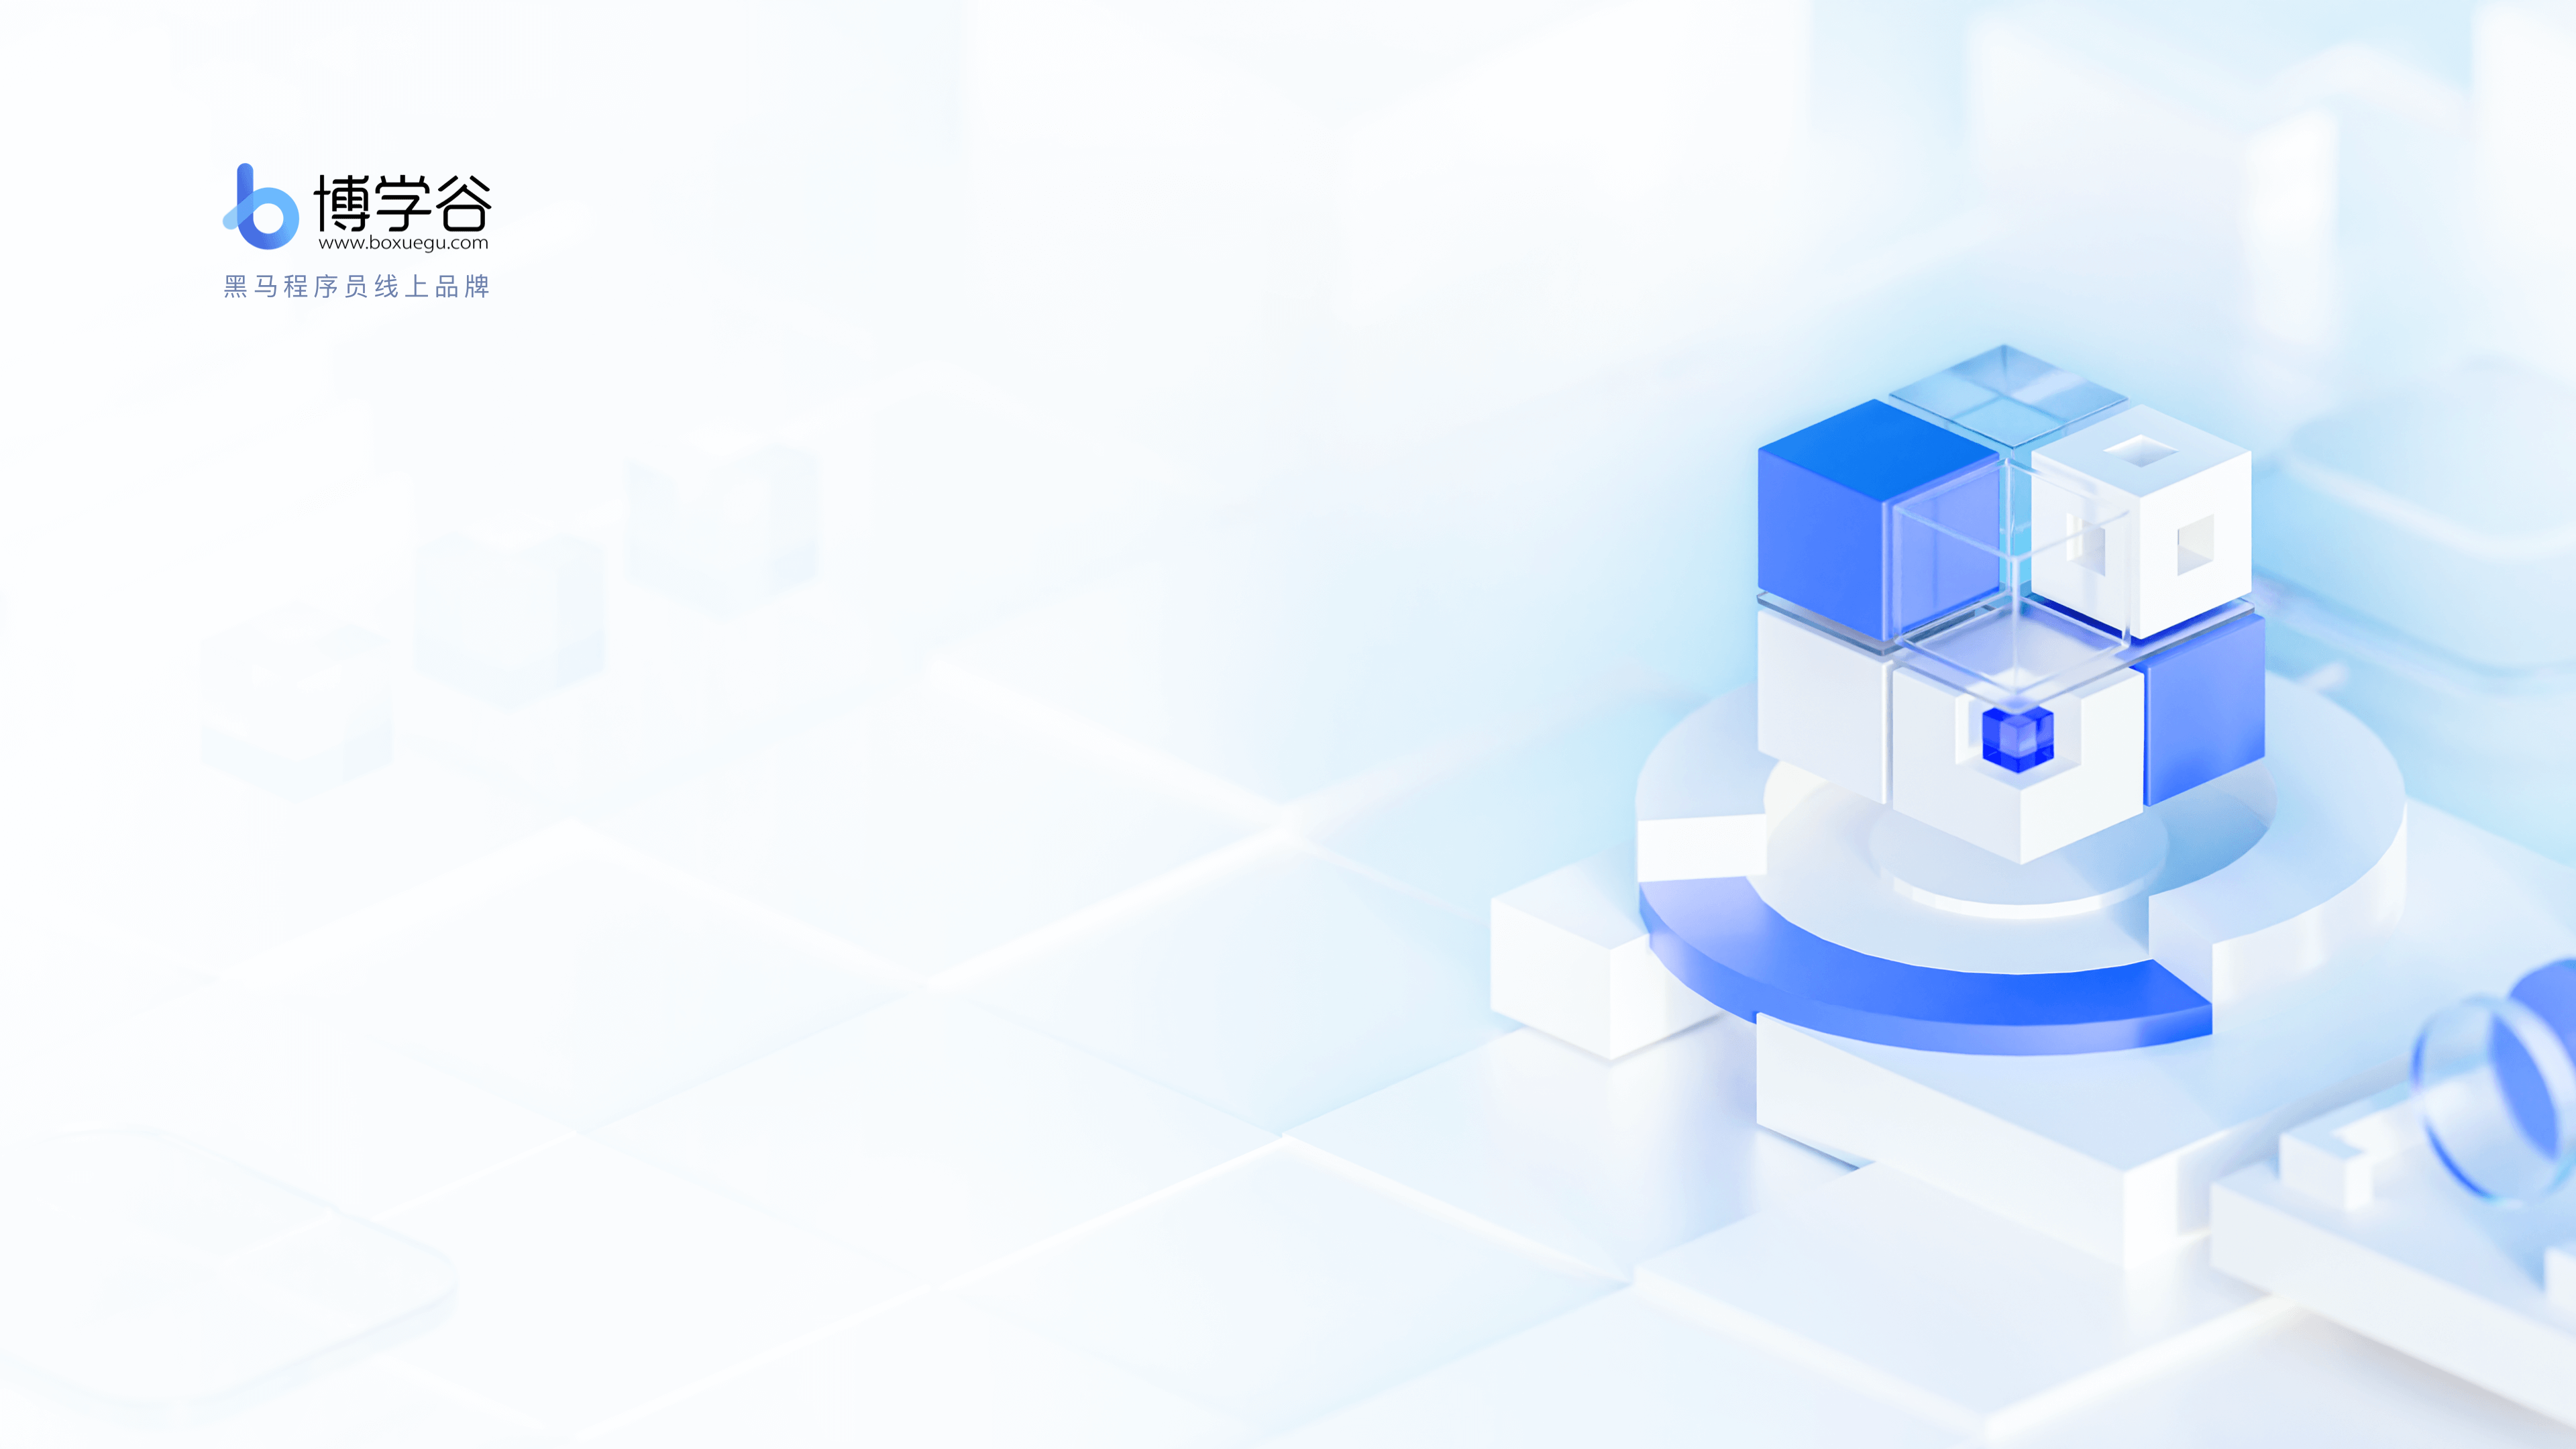

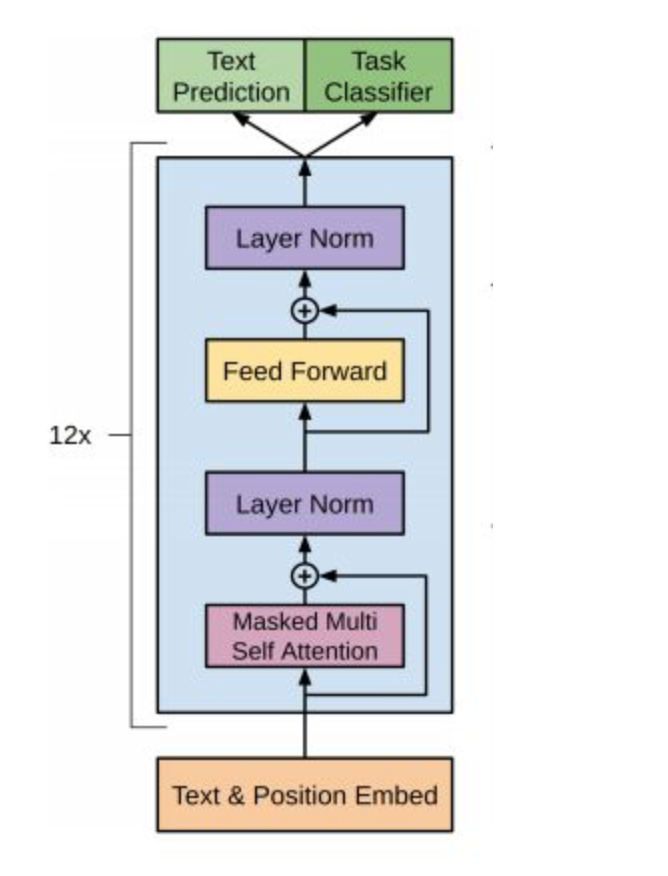

### 2.2 两阶段训练过程

**第一阶段：无监督预训练。** 给定序列 `U=[u₁,u₂,…,uₙ]`，模型最大化每个词在前文条件下的概率。输入经过词嵌入和位置嵌入得到 `h₀`，再经过多层 Decoder block，最后一层输出用于预测词表概率。

**第二阶段：有监督下游任务微调。** 预训练后的模型接收任务样本 `[x₁,x₂,…,xₙ]` 和标签 `y`，在模型上增加任务相关的输出层，通过监督学习最大化标签概率。不同任务需要设计相应的输入形式和分类层。


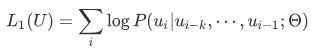

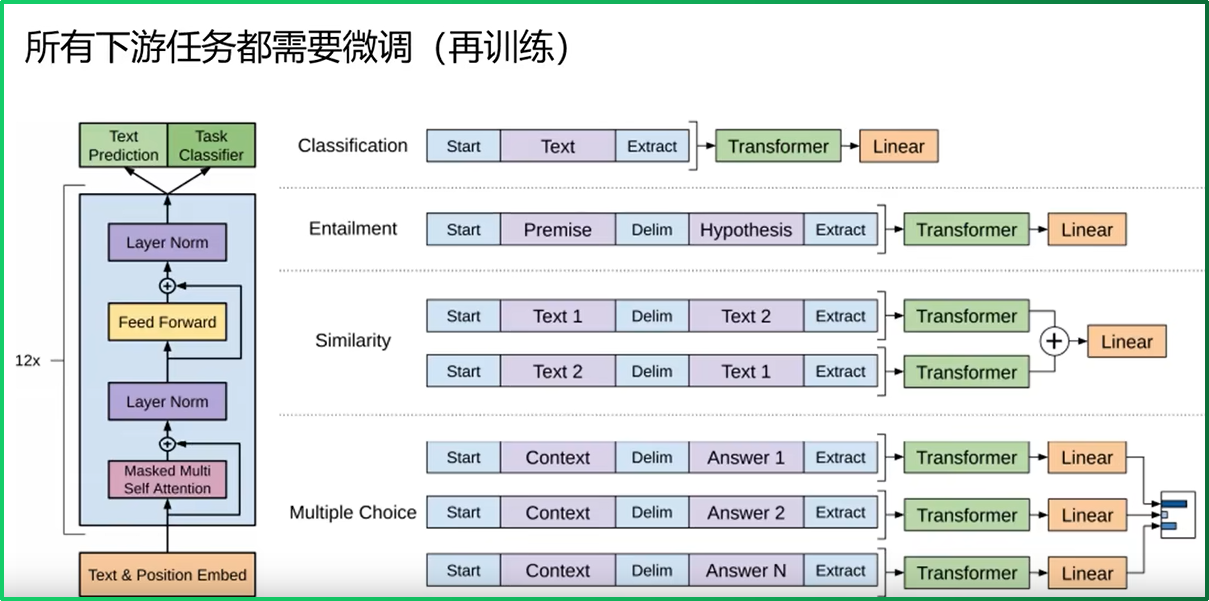

### 2.3 数据集、参数与特点

GPT-1 使用 BooksCorpus：约 5GB 文本、7400 万句以上，来自 7000 本不同风格的书籍。书籍文本包含较多高质量长句，有利于学习长距离依赖，也不容易与公开下游测试集完全重合。

| 参数 | 取值 |
| --- | --- |
| Transformer 层数 | 12 |
| 特征维度 | 768 |
| Transformer head 数 | 12 |
| 总参数量 | 1.17 亿 |

优点是更容易并行化，在多个任务上取得较好效果；缺点是语言模型单向，只能利用左侧上下文，并且每个下游任务都要准备数据并重新微调。


## 三、GPT-2：从任务微调走向 zero-shot

GPT-2 于 2019 年发布，论文是 *Language Models are Unsupervised Multitask Learners*。它没有大幅改变 GPT-1 的主体结构，而是使用更大的网络、更大的数据集和更长的输入，最大模型达到 15 亿参数、48 层。

### 3.1 结构改动

- LayerNorm 放到 Self-Attention 和 Feed Forward 之前，形成 Pre-LayerNorm，减少深层网络中的方差变化，使梯度更稳定。
- 在最后一个 Transformer block 后增加 LayerNorm。
- 最大输入长度从 512 扩大到 1024。

### 3.2 zero-shot 的核心思想

GPT-2 取消下游 fine-tuning，只进行无监督预训练。它的假设是：当模型容量足够大、数据覆盖足够广时，语言模型学习到的能力可以直接迁移到多个任务，不必为每个任务准备标注数据和任务专用训练。

为了让任务输入看起来像自然语言，任务会被改写成文本提示。例如翻译任务可以写成：

```text
translate to french, { english text }, { french text }
```

阅读理解任务可以写成：

```text
answer the question, { document }, { question }, { answer }
```

GPT-2 的 WebText 数据集约 800 万篇文章、约 40GB，主要来自 Reddit 高赞链接，并移除了涉及 Wikipedia 的文章以降低与测试集的重合。


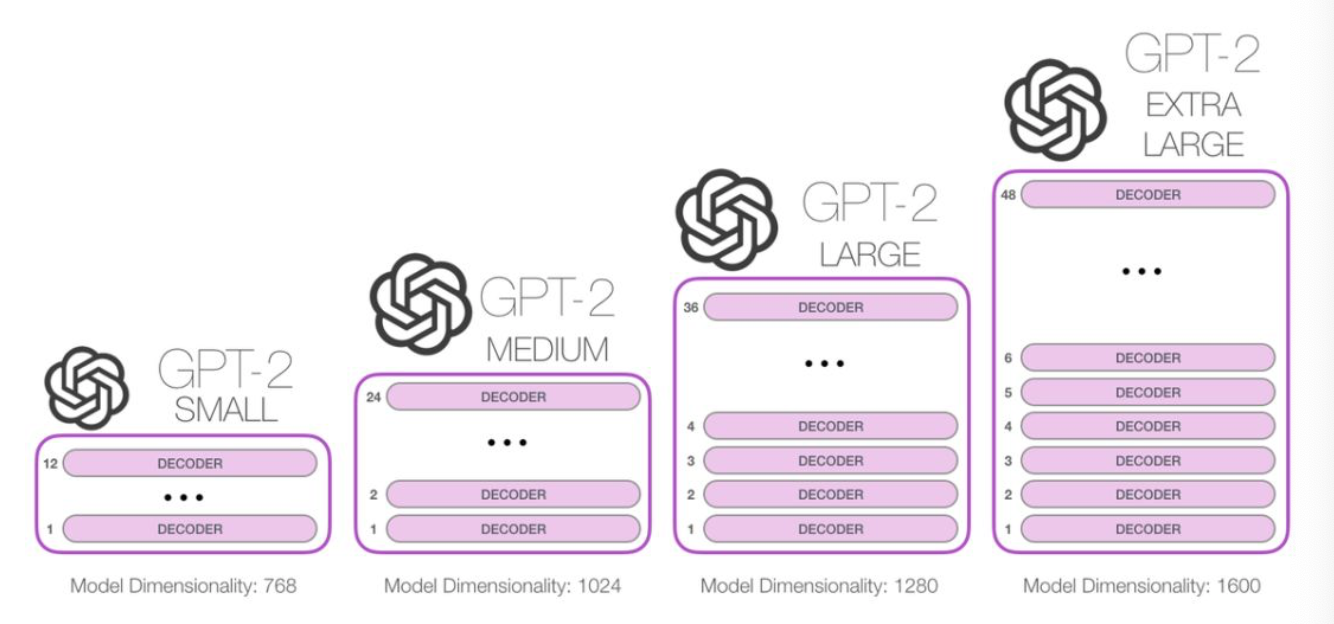

### 3.3 GPT-1 与 GPT-2 对比

| 对比项 | GPT-1 | GPT-2 |
| --- | --- | --- |
| 使用方式 | 预训练 + fine-tuning | 预训练后 zero-shot |
| 数据规模 | BooksCorpus，约 5GB | WebText，约 40GB |
| 最大参数量 | 约 1.17 亿 | 约 15 亿 |
| 最大序列长度 | 512 | 1024 |
| 结构 | 基础 Decoder-only | Pre-LayerNorm、末层 LayerNorm |

GPT-2 验证了海量数据和参数能够带来跨任务迁移，但课件也指出，它的无监督学习能力仍不稳定，部分任务上的效果甚至不如简单基线。


## 四、GPT-3：sparse attention 与情境学习

GPT-3 于 2020 年发布，论文是 *Language Models are Few-Shot Learners*。它延续 GPT 结构，但把重点放在模型规模、数据规模和情境学习（in-context learning）上。

### 4.1 sparse attention

传统 dense self-attention 中，每个 token 与其他 token 两两计算，复杂度为 `O(n²)`。Sparse attention 只让每个 token 与一部分 token 计算，课件以 `O(n log n)` 进行对比说明，从而减少显存和计算开销，支持更长输入。

- 局部距离较近的 token 重点关注；
- 远距离 token 以稀疏方式连接；
- 保留局部紧密相关、远程稀疏相关的结构。

最大 GPT-3 模型为 175B 参数，96 层 Transformer，head size 为 96，词向量维度 12288，文本长度 2048。


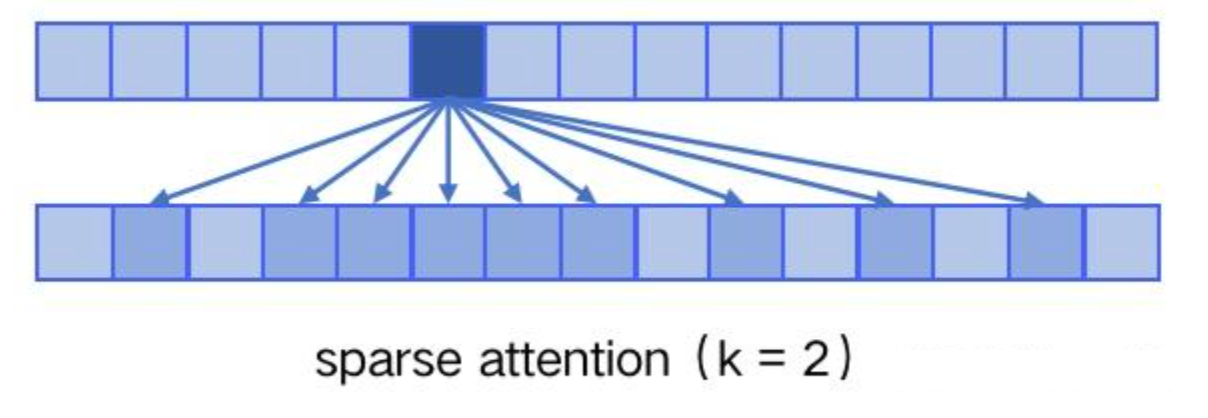

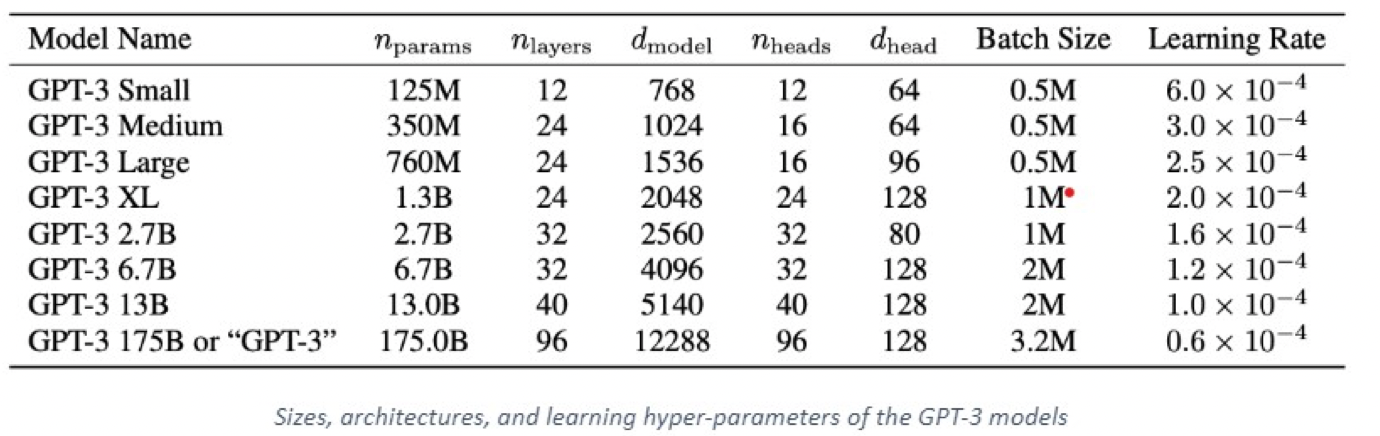

### 4.2 zero-shot、one-shot、few-shot

GPT-3 仍然只进行无监督预训练，推理时通过提示提供任务描述和少量示例，不更新模型参数：

- **Zero-shot**：只给出任务描述和待预测样本。
- **One-shot**：在待预测样本前加入一个示例。
- **Few-shot**：加入多个示例，让模型从上下文中理解任务。

这类方式称为 ICL（In-Context Learning），也可称为提示学习。它和 fine-tuning 的根本区别是：fine-tuning 会通过梯度回传更新模型参数；ICL 只在输入中提供示例，参数保持不变，且所需示例数量通常远少于完整微调数据。

课程给出的效果排序是：few-shot 通常最好，one-shot 次之，zero-shot 最弱。


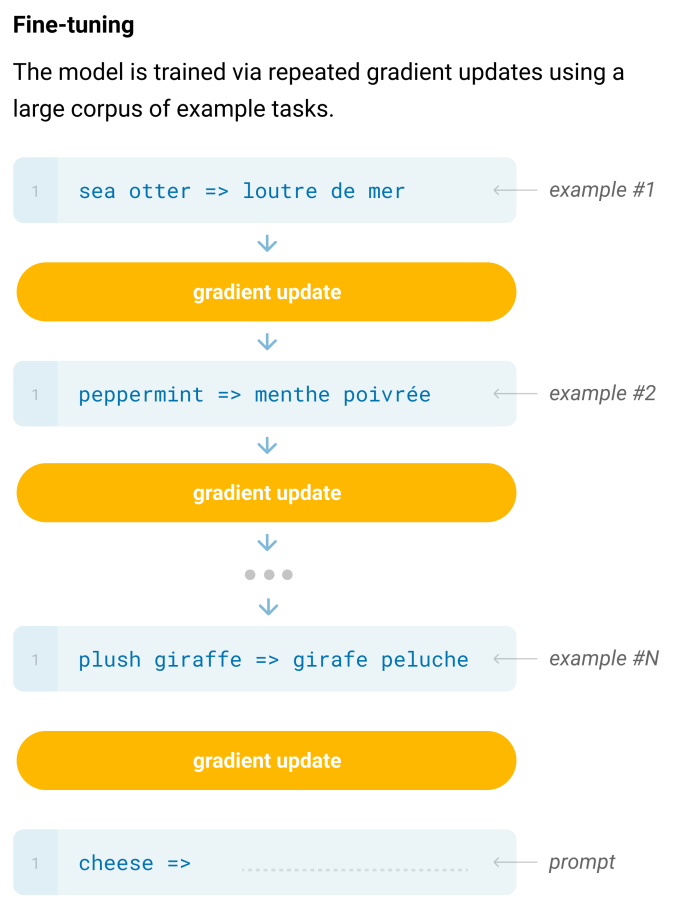

### 4.3 GPT-3 数据与局限

GPT-3 使用约 45TB 原始文本，课件列出的主要语料如下：

| 数据集 | token 数量 | 训练占比 |
| --- | ---: | ---: |
| Common Crawl（filtered） | 4100 亿 | 60% |
| WebText2 | 190 亿 | 22% |
| BOOK1 | 120 亿 | 8% |
| BOOK2 | 550 亿 | 8% |
| Wikipedia | 30 亿 | 2% |

优点是 few-shot 下可以接近甚至超过某些基于 fine-tuning 的方法；局限是训练成本极高，海量数据可能包含敏感内容，长文本生成可能重复、矛盾或衔接不佳，部分不在训练分布中的任务仍然难以处理。


## 五、ChatGPT：从生成模型到人类反馈对齐

ChatGPT 是基于 GPT 生成能力构建的对话模型。原始 GPT-3 能生成类似人类的文本，但不一定总能给出符合人类期望的回答，存在“能力不一致”问题。ChatGPT 使用 RLHF（Reinforcement Learning from Human Feedback，人类反馈强化学习）进一步训练，让模型输出更符合人类偏好。

### 5.1 强化学习的基本要素

强化学习是一种机器学习方法，关注智能体与环境的交互，以最大化累积回报为目标。核心要素是：

| 要素 | 含义 |
| --- | --- |
| Agent | 采取动作的智能体 |
| Environment | 智能体所处的环境 |
| State | 当前环境和智能体的状态 |
| Action | 智能体在状态下采取的动作 |
| Reward | 环境对动作的反馈 |
| Policy | 根据状态选择动作的策略 |

在每一步中，智能体观察 `s₁`，根据策略得到 `a₁`，环境返回 `s₂` 和 `r₁`，不断循环形成包含状态、动作和奖励的 trajectory。


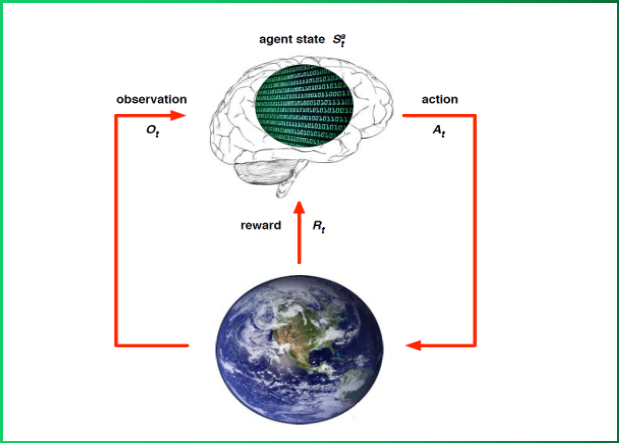

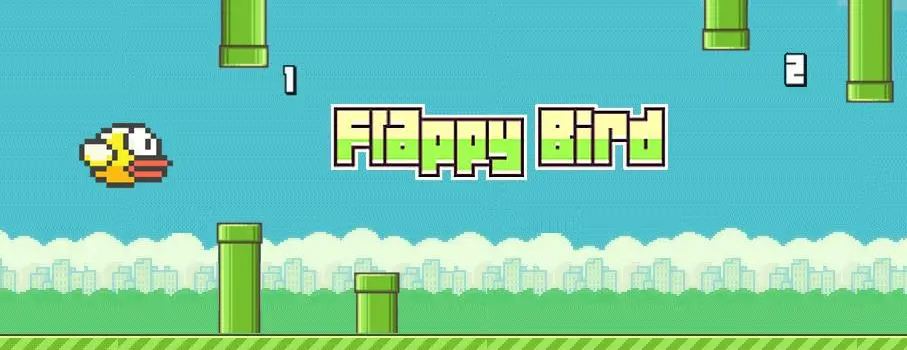

### 5.2 ChatGPT 的三阶段训练

**阶段一：监督微调（SFT）。** 人工标注者针对问题编写期望回答，用有标注数据训练预训练模型，使其适应对话任务。课件以 text-davinci-003 作为基线模型示例。

**阶段二：训练奖励模型（Reward Model）。** 对同一个问题，让 SFT 模型生成多个回答，人工从好到坏排序，形成偏好数据集。奖励模型输入 `[prompt, response]`，输出一个表示人类偏好程度的标量奖励值。课件中还给出，排序数据规模约为 SFT 数据规模的 10 倍，奖励模型是参数约 6 亿的 GPT-3 蒸馏模型。

**阶段三：PPO 强化学习。** 把问题输入 ChatGPT/PPO 模型得到回答，再将回答交给奖励模型打分，PPO 根据奖励更新策略，使模型更倾向于得到高分的输出。


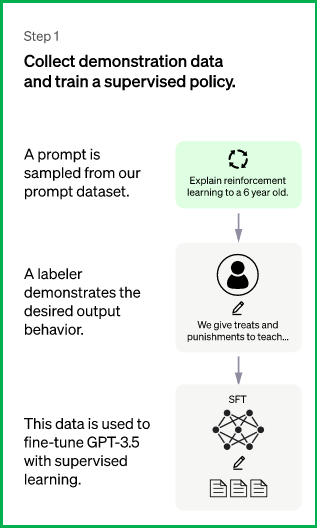

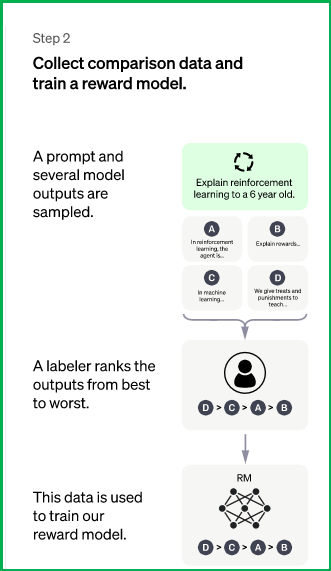

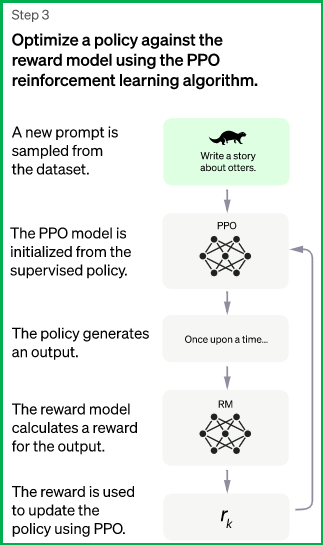

## 六、主流开源大模型概览

ChatGPT 的快速发展带动了开源模型生态。课件将开源模型按基础模型分为几条路线：

- ChatGLM 衍生模型：wenda、ChatSQL 等；
- LLaMA 衍生模型：Alpaca、Vicuna、BELLE、Phoenix、Chimera 等；
- BLOOM 衍生模型：BLOOMZ、BELLE、Phoenix 等；
- Baichuan 衍生模型：Baichuan-7B、Baichuan-13B、Baichuan2-13B 等。

后面的模型虽然都大多采用 Decoder-only，但在预训练目标、分词器、归一化、激活函数、位置编码和注意力形式上有不同设计。


## 七、ChatGLM-6B：Prefix-Decoder 与自回归空白填充

ChatGLM-6B 由清华大学提出，基于 GLM（General Language Model）架构，支持中英双语，约 62 亿参数。课件介绍其使用约 1T 中英文 token 训练，中英文比例约为 1:1，并结合监督微调、反馈自助和人类反馈强化学习。

### 7.1 GLM 的训练目标

GLM 是基于**自回归空白填充目标**的通用预训练框架：

1. 在文本中随机挖出若干连续片段。
2. 用 `[M]` 替换这些片段，并可以打乱片段顺序。
3. 每个片段输入前加 `[S]`，输出后加 `[E]`。
4. 模型按照自回归方式重建这些片段。

Part A 可以看到自身但看不到 Part B；Part B 可以看到 Part A 和同一片段中已经生成的前文。二维位置编码同时表示片段之间和片段内部的位置关系。


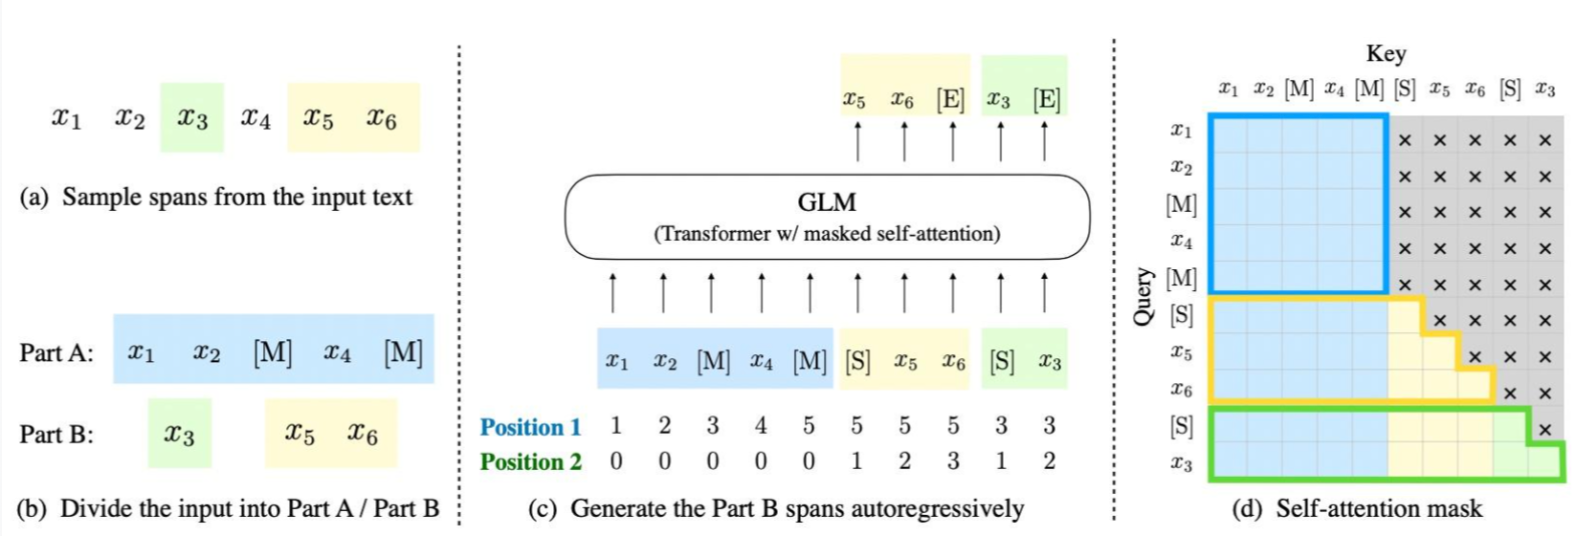

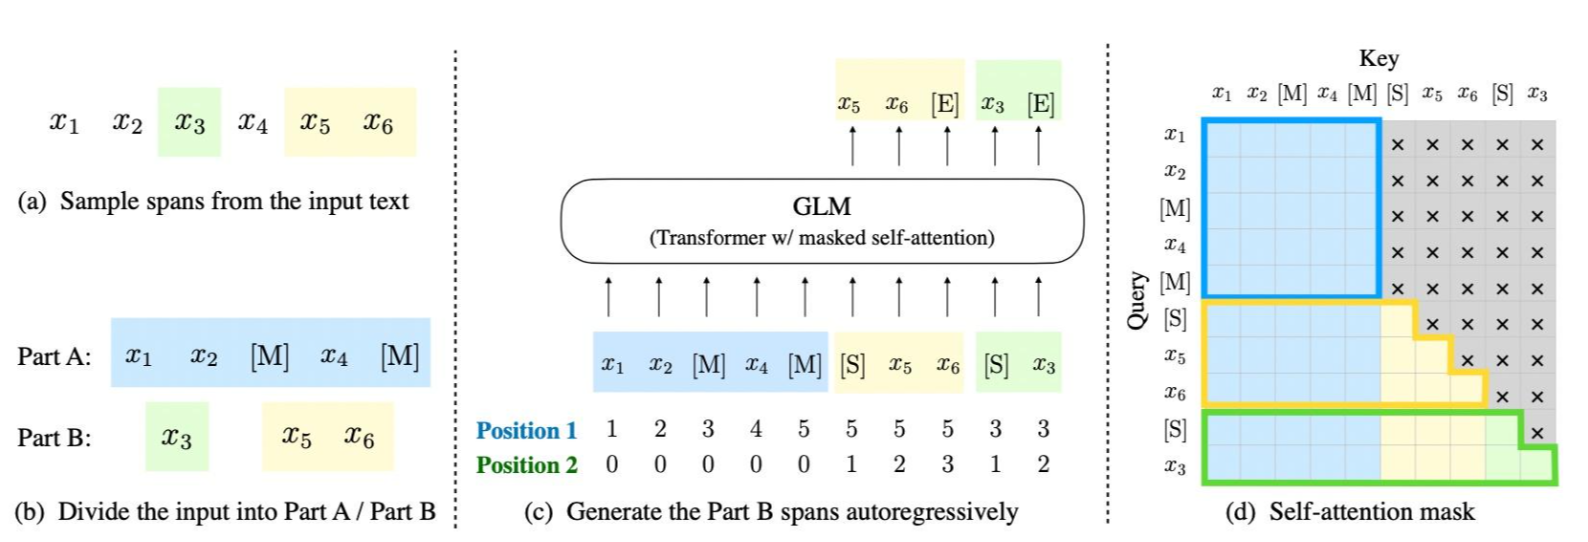

### 7.2 结构改动与配置

GLM 采用 Transformer Decoder 类模块：整体任务都看作生成任务，但部分位置可以双向可见，因此称为 Prefix-Decoder，而不是严格的单向 Decoder。相对原始 Decoder，课件列出以下改动：

- embedding 层梯度缩减，效果相当于将梯度缩小约 10 倍；
- 使用基于 Deep Norm 的 post LayerNorm；
- 用 GeGLU 替换 ReLU；
- 去除绝对位置编码，使用 RoPE。

| 配置 | 数值 |
| --- | ---: |
| 参数量 | 6.2B |
| 隐藏层维度 | 4096 |
| 层数 | 28 |
| 注意力头数 | 32 |
| 训练数据 | 1T |
| 词表大小 | 130528 |
| 最大长度 | 2048 |

课件给出的推理显存参考：FP16 约 13GB，INT8 约 10GB，INT4 约 6GB；高效参数微调对应显存约为 14GB、9GB 和 7GB。


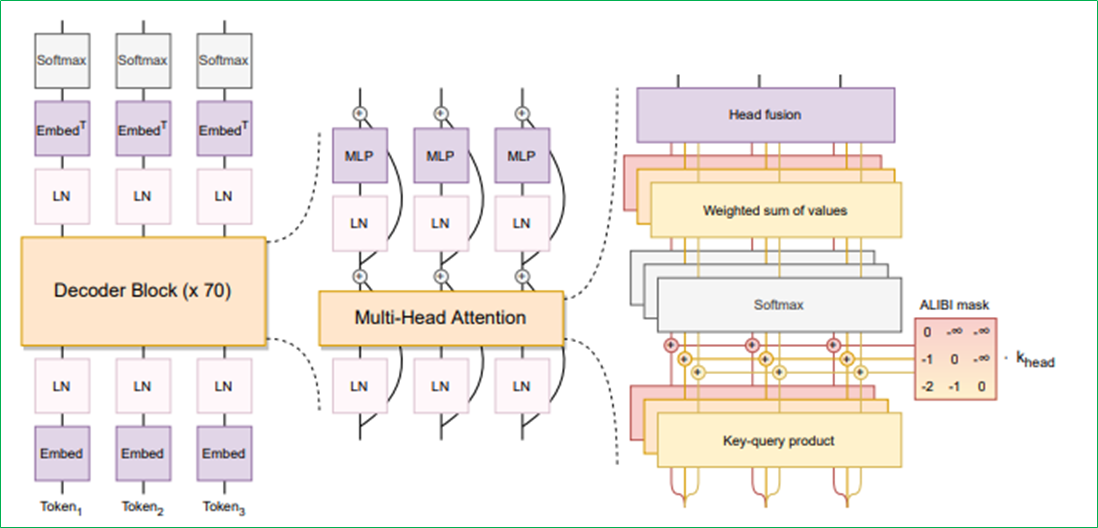

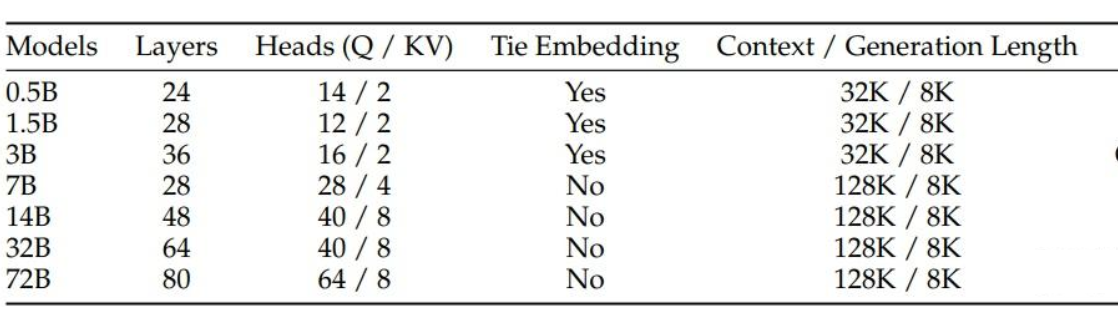

### 7.3 ChatGLM 迭代版本

- **ChatGLM2-6B**：数学任务等对话能力提升；借助 FlashAttention 支持 32K 上下文；引入 Multi-Query Attention，降低显存并提升推理速度，INT4 模型的对话长度从 1K 提升到 8K。
- **ChatGLM3-6B**：增加多模态理解、代码生成与执行、网络搜索增强，语义和逻辑能力进一步提升。

ChatGLM 的优势是部署门槛相对低、中文支持较好；限制是模型容量小，记忆、语言能力和多轮对话能力相对有限。


## 八、LLaMA：高效的 Decoder-only 基础模型

LLaMA（Large Language Model Meta AI）由 Meta AI 于 2023 年发布，提供 7B、13B、33B、65B 四种规模。训练语料以英文和拉丁语系为主，包含 GitHub 代码，课程资料强调原始训练数据不包含中、日、韩文。

训练目标仍是根据上文预测下一个词；tokenizer 使用 BPE，词表约 32000，中文 token 很少，因此中文分词效率较低。

### 8.1 结构改动

- 使用 Pre-LayerNorm，并采用 RMSNorm；
- 用 SwiGLU 替代 ReLU；
- 去掉绝对位置编码，使用 RoPE。

RMSNorm 去掉了 LayerNorm 中减均值的步骤，计算更简化。RoPE 通过旋转方式编码相对位置信息，SwiGLU 则增强前馈网络的非线性表达。


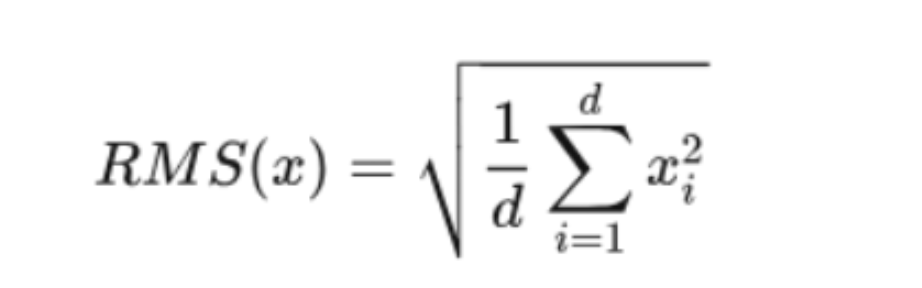

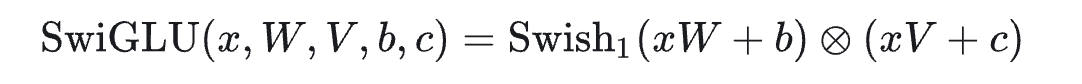

### 8.2 LLaMA-7B 配置与版本

| 配置 | 数值 |
| --- | ---: |
| 参数量 | 6.7B |
| 隐藏层维度 | 4096 |
| 层数 | 32 |
| 注意力头数 | 32 |
| 训练数据 | 1T |
| 词表大小 | 32000 |
| 最大长度 | 2048 |

LLaMA 的优点是参数效率较高，课件提到 13B 版本在多数基准上可以超过 175B 的 GPT-3，并能在单块 V100 上运行；缺点是可能生成偏见、毒性或虚假内容，中文效果受语料和 tokenizer 限制。

衍生模型包括 Alpaca、Vicuna、BELLE 和 Chinese LLaMA。LLaMA 2 增加约 40% 训练语料，将上下文长度提升到 4096，并训练了 chat 版本；课件还介绍 LLaMA 3 扩大词表、使用 GQA，并继续扩充预训练数据。


## 九、BLOOM：多语言开源模型

BLOOM 由 Hugging Face 组织训练，语料覆盖英语、中文、法语、西班牙语、葡萄牙语等 46 种语言，并包含 13 种编程语言。训练数据约 1.5TB，中文占比约 16.2%。模型规模从 560M 到 176B，训练目标是根据上文预测下一个词；多语言 tokenizer 使用 BPE，词表大小约 250880。

### 9.1 结构与配置

- Decoder-only 架构；
- embedding 层后增加 LayerNorm；
- 使用 Pre-LayerNorm；
- 使用 GeLU 激活函数；
- 去掉绝对位置编码，采用相对位置编码 ALiBi，以改善长度外推。

| 配置 | BLOOM-176B |
| --- | ---: |
| 参数量 | 176B |
| 隐藏层维度 | 14336 |
| 层数 | 70 |
| 注意力头数 | 112 |
| 训练数据 | 366B tokens |
| 词表大小 | 250880 |
| 最大长度 | 2048 |

课件记录的训练环境是 384 张 NVIDIA A100 80GB，训练约 3.5 个月。BLOOM 的优势是多语言适应性好，缺点同样包括偏见、毒性和幻觉风险。衍生应用包括面向金融领域的轩辕，以及对 BLOOMZ 进行指令微调的 BELLE。


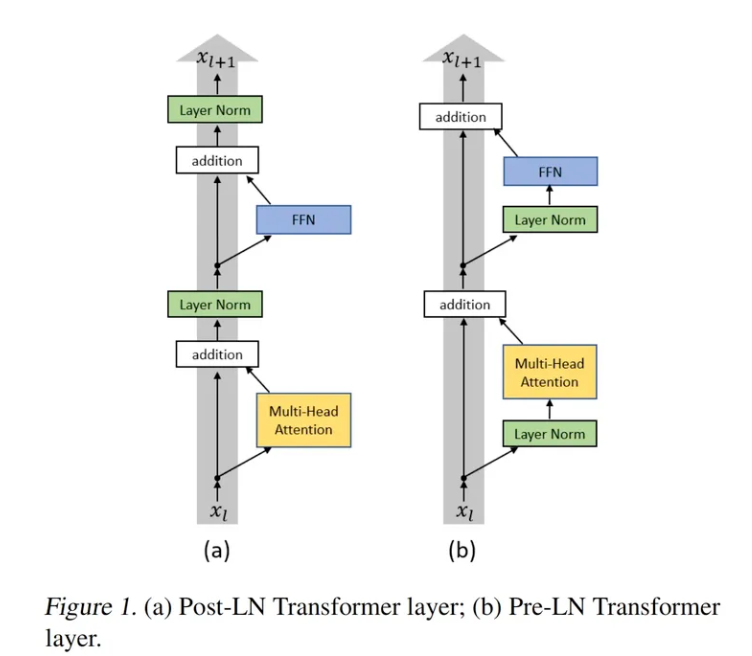

## 十、Baichuan-7B：中英双语开源模型

Baichuan-7B 由百川智能于 2023 年 6 月发布，支持中英双语，使用约 1.2T token 训练，词表大小 64000，数据包括开源中英文语料、中文互联网数据和高质量知识数据。

它与 LLaMA 类似，也是 Decoder-only 架构，采用：

- Pre-LayerNorm + RMSNorm；
- SwiGLU 激活函数；
- RoPE 旋转位置编码；
- BPE tokenizer。

| 配置 | 数值 |
| --- | ---: |
| 参数量 | 7B |
| 隐藏层维度 | 4096 |
| 层数 | 32 |
| 注意力头数 | 32 |
| 训练数据 | 1.2T |
| 词表大小 | 64000 |
| 最大长度 | 4096 |

Baichuan-13B 在此基础上增加参数和数据，支持 4096 上下文，并提供 INT8、INT4 量化版本，降低消费级显卡部署门槛；课件还强调其对学术研究开放，并可申请商用许可。


## 十一、Qwen：分组查询注意力与长上下文

Qwen 是阿里巴巴训练并开源的系列大语言模型，课程资料介绍了 Qwen、Qwen1.5、Qwen2 和 Qwen2.5 等系列，覆盖从 1.8B 到 72B 等不同规模。

### 11.1 模型结构

- **GQA（Grouped-Query Attention）**：多个 query 头共享较少的 key/value 头，减少 KV cache，提升推理效率。
- **SwiGLU**：增强前馈网络的非线性表达能力。
- **RoPE**：改善长序列位置建模。
- **RMSNorm**：简化归一化计算并提升训练稳定性。

### 11.2 Qwen2.5-7B-Instruct 配置

| 配置 | 数值 |
| --- | ---: |
| 参数量 | 7B |
| 隐藏层维度 | 3584 |
| 层数 | 28 |
| 注意力头数 | 28 个 query、4 个 key-value |
| 训练数据 | 1.2T（课件配置表） |
| 词表大小 | 151936 |
| 最大长度 | 32768 |

课件的特点总结强调：Qwen2.5 在预训练和后训练阶段继续扩大数据，并通过监督微调和多阶段强化学习提升长文本生成、结构化数据分析和指令遵循能力。


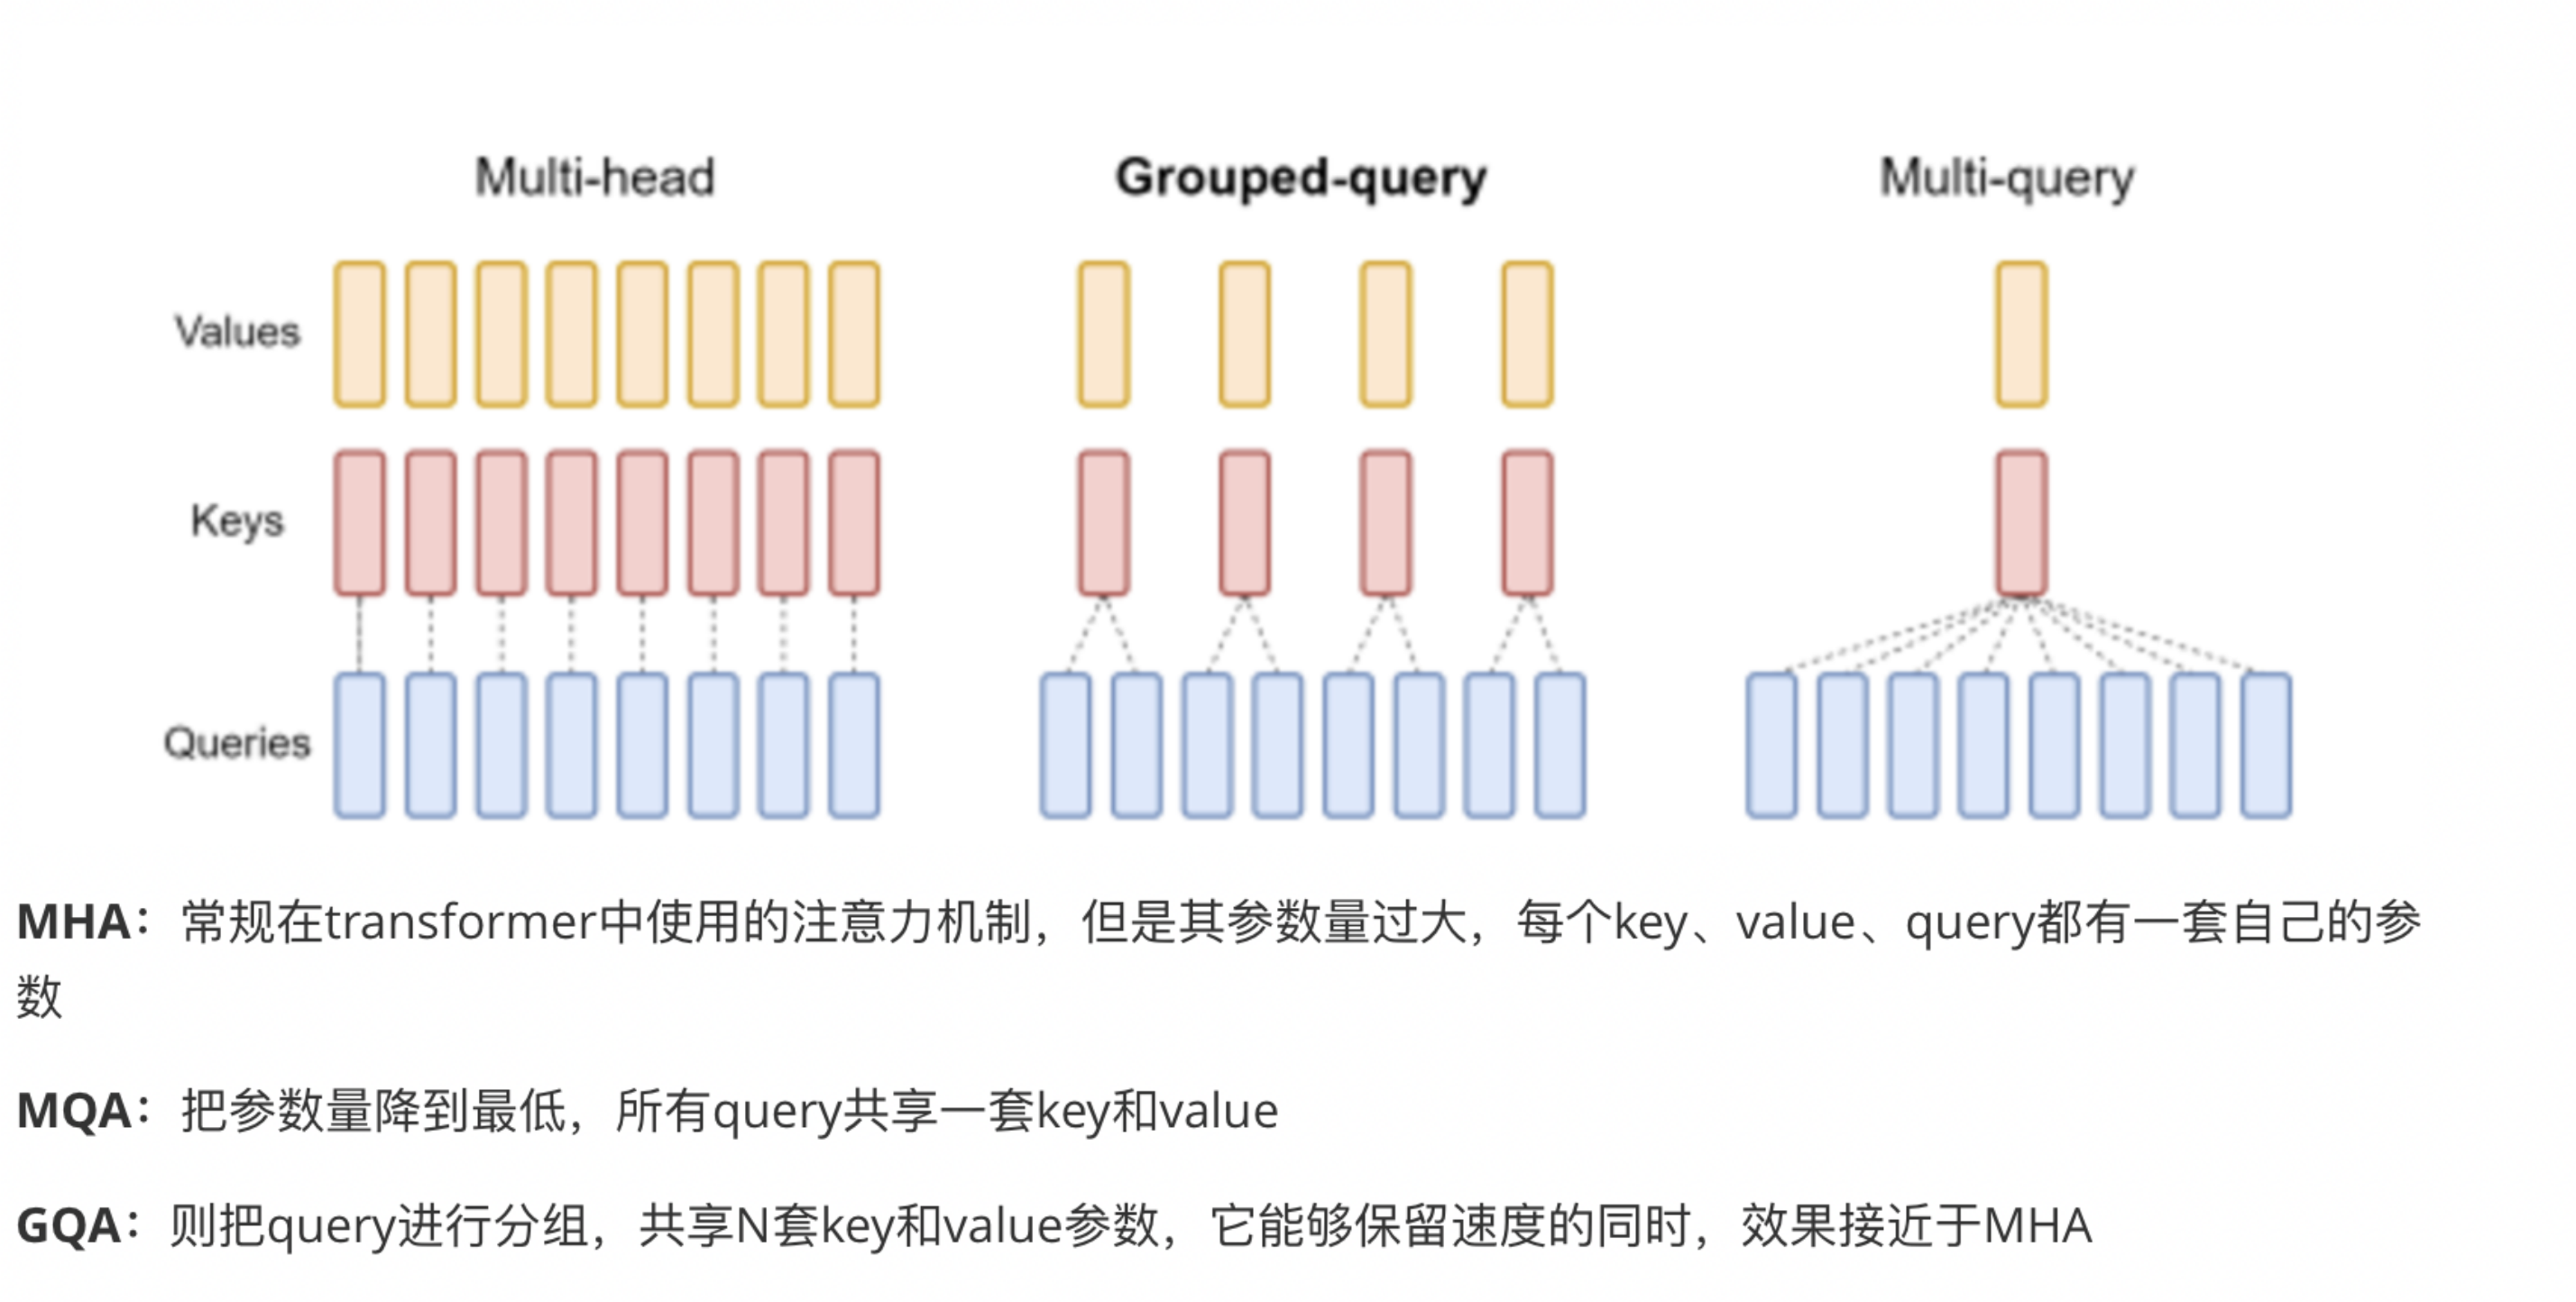

## 十二、本章总结

- GPT-1 采用“无监督预训练 + 下游任务微调”，GPT-2 用更大模型和数据探索 zero-shot，GPT-3 通过 ICL 支持 one-shot、few-shot。
- ChatGPT 的关键不只是 GPT 规模，还包括 SFT、奖励模型和 PPO 强化学习组成的 RLHF 流程。
- ChatGLM 用自回归空白填充和 Prefix-Decoder 兼顾理解与生成；LLaMA、Baichuan、Qwen 和 BLOOM 都以 Decoder-only 为主，但在语言覆盖、归一化、激活函数、位置编码和注意力方面各有侧重。
- 读模型配置时，不能只看参数量，还要同时看训练数据、上下文长度、词表、注意力结构、显存要求和是否经过指令/人类反馈对齐。
